<a href="https://colab.research.google.com/github/NoahJuganar/NoahJuganar-DataScience-GenAI-Submissions/blob/main/Copy_of_5_02_Modelling_Hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 5.02 Modelling Hackathon
We'll get a chance in this seminar to practice for the in-class test, and also to put what we have learned into practice.

To speed things up, I have done the data/feature engineering for you, you will just need to build it into a data science model. As before, you can use the code from [GitHub](https://github.com/MJMortensonWarwick/IB2AD0_Data_Science_GenerativeAI), from the internet, and/or use the Gemini AI tools.

This is an artificial dataset, and we will be predicting if students achieve a passing grade, which we will call anything above a "D".

We'll start by importing the data:

In [59]:
from google.colab import files
upload = files.upload()

Saving students_two.csv to students_two (6).csv


Now we will get the data into Pandas and inspect it:

In [60]:
import pandas as pd
df = pd.read_csv("students_two.csv")

df.head()

,Id,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,5001,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,5002,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,5003,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,5004,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,5005,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Let's check for missing values:

In [61]:
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,1
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


Only one missing value. Let's just drop it out of laziness:

In [62]:
df.dropna(inplace=True)
df.isnull().sum()

,0
Id,0
Student_Age,0
High_School_Type,0
Scholarship,0
Additional_Work,0
Sports_activity,0
Transportation,0
Weekly_Study_Hours,0
Attendance,0
Reading,0


We have an ID column we know won't be predictive ... so let's drop it:

In [63]:
df = df.drop(["Id"], axis=1)
df.head()

,Student_Age,High_School_Type,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade
0,21,Other,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA
1,20,Other,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA
2,21,State,50%,No,No,Private,2,Never,No,No,No,Yes,AA
3,18,Private,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA
4,22,Private,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA


Next we will convert some of the text features to numbers:

In [64]:
# High school
print(df['High_School_Type'].unique())

['Other' 'State' 'Private']


We can't easily convert these to a number range. Instead we should use one-hot encoding:

In [65]:
df = pd.get_dummies(df, columns=['High_School_Type'], drop_first=True, dtype=int)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,50%,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,50%,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,50%,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,50%,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,50%,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


We have converted this to two columns (on the far right) - "High_School_Type_Private" and "High_School_Type_State". We do not need the "Other" type as if the student is "Other" then both "Private" and "State" will be 0 (a unique combination). This is controlled by the command _drop\_first=True_. We also specify the data type (_dtype_) as __int__ so we return 0s and 1s rather than True and False.

Next we can look at Scholarship. It needs to be converted from a text representation of a percentage to a number:

In [66]:
df['Scholarship'] = df['Scholarship'].str.replace('%', '').astype(float) / 100
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,Yes,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,Yes,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,No,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,Yes,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,No,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


"Additional_Work" is next:

In [67]:
# Additional work
print(df['Additional_Work'].unique())

['Yes' 'No']


Two values, so we can convert to 0 and 1:

In [68]:
df['Additional_Work'] = df['Additional_Work'].map({'Yes': 1, 'No': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Let's speed up now:

In [69]:
categorical_cols = ['Sports_activity', 'Transportation', 'Attendance', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work', 'Grade']

for col in categorical_cols:
    print(f"Unique values for '{col}': {df[col].unique()}")

Unique values for 'Sports_activity': ['No' 'Yes']
Unique values for 'Transportation': ['Private' 'Bus']
Unique values for 'Attendance': ['Always' 'Never' 'Sometimes' '3']
Unique values for 'Reading': ['Yes' 'No']
Unique values for 'Notes': ['Yes' 'No' '6']
Unique values for 'Listening_in_Class': ['No' 'Yes' '6']
Unique values for 'Project_work': ['No' 'Yes']
Unique values for 'Grade': ['AA' 'BA' 'CC' 'Fail' 'BB' 'CB' 'DD' 'DC']


The values of '6' in 'Notes' and 'Listening_in_Class' make no sense, and neither do '3' for 'Attendance'. We'll be lazy and drop these rows (really we should check with an SME):

In [70]:
df = df[(df['Notes'] != '6') & (df['Listening_in_Class'] != '6') & (df['Attendance'] != '3')]
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,No,Private,0,Always,Yes,Yes,No,No,AA,0,0
1,20,0.5,1,No,Private,0,Always,Yes,No,Yes,Yes,AA,0,0
2,21,0.5,0,No,Private,2,Never,No,No,No,Yes,AA,0,1
3,18,0.5,1,No,Bus,2,Always,No,Yes,No,No,AA,1,0
4,22,0.5,0,No,Bus,12,Always,Yes,No,Yes,Yes,AA,1,0


Now we can convert all those "Yes" / "No" columns to 0 and 1.

In [71]:
binary_cols = ['Sports_activity', 'Reading', 'Notes', 'Listening_in_Class', 'Project_work']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,Private,0,Always,1,1,0,0,AA,0,0
1,20,0.5,1,0,Private,0,Always,1,0,1,1,AA,0,0
2,21,0.5,0,0,Private,2,Never,0,0,0,1,AA,0,1
3,18,0.5,1,0,Bus,2,Always,0,1,0,0,AA,1,0
4,22,0.5,0,0,Bus,12,Always,1,0,1,1,AA,1,0


We can also do this with "Transportation":

In [72]:
df['Transportation'] = df['Transportation'].map({'Private': 1, 'Bus': 0})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,Always,1,1,0,0,AA,0,0
1,20,0.5,1,0,1,0,Always,1,0,1,1,AA,0,0
2,21,0.5,0,0,1,2,Never,0,0,0,1,AA,0,1
3,18,0.5,1,0,0,2,Always,0,1,0,0,AA,1,0
4,22,0.5,0,0,0,12,Always,1,0,1,1,AA,1,0


For Attendance an ordinal range makes sense:

In [73]:
df['Attendance'] = df['Attendance'].map({'Never': 0, 'Sometimes': 1, 'Always': 2})
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,2,1,1,0,0,AA,0,0
1,20,0.5,1,0,1,0,2,1,0,1,1,AA,0,0
2,21,0.5,0,0,1,2,0,0,0,0,1,AA,0,1
3,18,0.5,1,0,0,2,2,0,1,0,0,AA,1,0
4,22,0.5,0,0,0,12,2,1,0,1,1,AA,1,0


This just leaves the target - 'Grade'. To make the problem binary we'll convert 'Fail' and any grade that includes a 'D' as 0 (for fail) and the rest as 1 (pass):

In [74]:
df['Grade'] = df['Grade'].apply(lambda x: 0 if x == 'Fail' or 'D' in x else 1)
df.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,Grade,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,2,1,1,0,0,1,0,0
1,20,0.5,1,0,1,0,2,1,0,1,1,1,0,0
2,21,0.5,0,0,1,2,0,0,0,0,1,1,0,1
3,18,0.5,1,0,0,2,2,0,1,0,0,1,1,0
4,22,0.5,0,0,0,12,2,1,0,1,1,1,1,0


The code has a new function `lambda`. A lambda function in Python is a small, anonymous function. It's defined using the `lambda` keyword and can take any number of arguments, but can only have one expression. The expression is evaluated and returned. They are often used for short, simple operations where a full function definition would be overly verbose, like in the apply method we just used. Although the function is new, the actual mechanics are quite simple. If the data is "Fail" or contains "D" return 0, and else return 1.

As this is the target we will create a new variable from it and then drop it from the main data:

In [75]:
Y_values = df[['Grade']].values.ravel() # change to list

Y_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1])

In [76]:
X_values = df.drop(['Grade'], axis=1)
X_values.head()

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,21,0.5,1,0,1,0,2,1,1,0,0,0,0
1,20,0.5,1,0,1,0,2,1,0,1,1,0,0
2,21,0.5,0,0,1,2,0,0,0,0,1,0,1
3,18,0.5,1,0,0,2,2,0,1,0,0,1,0
4,22,0.5,0,0,0,12,2,1,0,1,1,1,0


We can now scale X:

In [77]:
from sklearn.preprocessing import MinMaxScaler

# create a MinMaxScaler object
scaler = MinMaxScaler()

# fit and transform the data and convert back to DataFrame
X_values = pd.DataFrame(scaler.fit_transform(X_values), columns=X_values.columns)
X_values

,Student_Age,Scholarship,Additional_Work,Sports_activity,Transportation,Weekly_Study_Hours,Attendance,Reading,Notes,Listening_in_Class,Project_work,High_School_Type_Private,High_School_Type_State
0,0.375,0.333333,1.0,0.0,1.0,0.000000,1.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.250,0.333333,1.0,0.0,1.0,0.000000,1.0,1.0,0.0,1.0,1.0,0.0,0.0
2,0.375,0.333333,0.0,0.0,1.0,0.166667,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,0.000,0.333333,1.0,0.0,0.0,0.166667,1.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.500,0.333333,0.0,0.0,0.0,1.000000,1.0,1.0,0.0,1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,0.500,0.333333,1.0,1.0,1.0,0.000000,1.0,0.0,1.0,0.0,1.0,0.0,1.0
136,0.000,0.666667,0.0,0.0,1.0,0.000000,0.0,0.0,1.0,1.0,0.0,0.0,1.0
137,0.000,0.666667,0.0,0.0,1.0,0.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.0
138,0.500,0.666667,1.0,1.0,0.0,1.000000,0.5,0.0,1.0,0.0,1.0,0.0,1.0


And now we can split into training and test:

In [78]:
# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_values, Y_values, test_size = 0.2, random_state=1984, stratify=Y_values)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(112, 13)
(28, 13)
(112,)
(28,)


And now its time for modelling ...



Your turn :)

## Step 2: Baseline and evaluation metrics
Our task is binary classification: predict whether a student passes (1) or fails (0). Because passing students outnumber failing students, accuracy alone can be misleading. We use macro F1 as our primary comparison metric because it gives both classes equal importance. We also report accuracy, macro precision, macro recall and recall for failing students (class 0). We compare models using five-fold stratified cross-validation on training data only. The final test set remains untouched until later.

In [79]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import f1_score, recall_score, make_scorer

# Recreate the split from the unscaled, lecturer-prepared DataFrame.
# The lecturer's existing variables are preserved.
X_hack = df.drop(columns=['Grade']).copy()
y_hack = df['Grade'].astype(int).to_numpy()

assert X_hack.isna().sum().sum() == 0, 'Missing feature values detected.'
assert len(X_hack.select_dtypes(exclude='number').columns) == 0, 'Non-numeric features detected.'
assert set(np.unique(y_hack)) == {0, 1}, 'Target must contain 0 and 1.'

X_train_hack, X_test_hack, y_train_hack, y_test_hack = train_test_split(
    X_hack, y_hack, test_size=0.2, random_state=1984, stratify=y_hack
)

cv_hack = StratifiedKFold(n_splits=5, shuffle=True, random_state=1984)

scoring_hack = {
    'accuracy': 'accuracy',
    'macro_precision': 'precision_macro',
    'macro_recall': 'recall_macro',
    'macro_f1': 'f1_macro',
    'fail_recall': make_scorer(recall_score, pos_label=0, zero_division=0)
}

def evaluate_hack(name, model):
    scores = cross_validate(
        model, X_train_hack, y_train_hack,
        cv=cv_hack, scoring=scoring_hack, n_jobs=1
    )
    model.fit(X_train_hack, y_train_hack)
    train_predictions = model.predict(X_train_hack)
    return {
        'Model': name,
        'CV Macro F1': scores['test_macro_f1'].mean(),
        'CV Macro F1 SD': scores['test_macro_f1'].std(),
        'CV Accuracy': scores['test_accuracy'].mean(),
        'CV Macro Precision': scores['test_macro_precision'].mean(),
        'CV Macro Recall': scores['test_macro_recall'].mean(),
        'CV Fail Recall': scores['test_fail_recall'].mean(),
        'Train Macro F1': f1_score(
            y_train_hack, train_predictions, average='macro', zero_division=0
        )
    }

print('Full dataset:', X_hack.shape)
print('Training:', X_train_hack.shape)
print('Reserved test:', X_test_hack.shape)
print('Class counts (0 = fail, 1 = pass):')
print(pd.Series(y_hack).value_counts().sort_index())

results_hack = []
baseline_hack = DummyClassifier(strategy='most_frequent')
results_hack.append(evaluate_hack('Majority-class baseline', baseline_hack))
display(pd.DataFrame(results_hack).round(3))

Full dataset: (140, 13)
Training: (112, 13)
Reserved test: (28, 13)
Class counts (0 = fail, 1 = pass):
0     37
1    103
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

,Model,CV Macro F1,CV Macro F1 SD,CV Accuracy,CV Macro Precision,CV Macro Recall,CV Fail Recall,Train Macro F1
0,Majority-class baseline,0.423,0.002,0.732,0.366,0.5,0.0,0.423


The majority-class baseline simply predicts the most frequent class (class 1, passing) for every observation. Consequently, while it yields an inflated accuracy (~72.9%) on this imbalanced dataset, it has zero recall for failing students (class 0) and a poor CV Macro F1 (~0.422) because it fails to represent the minority class at all.

## Step 3: Train and compare classification models
We compare four algorithms from the course: Logistic Regression, Decision Tree, Random Forest and Gradient Boosting. The models initially use default or near-default hyperparameters. For Logistic Regression, a pipeline scales the features separately inside each cross-validation training fold, preventing scaling-related information leakage. Tree-based models use the unscaled features. We compare their five-fold cross-validation scores and their training scores to identify promising models and potential overfitting.

Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: Gradient Boosting


,Model,CV Macro F1,CV Macro F1 SD,CV Accuracy,CV Macro Precision,CV Macro Recall,CV Fail Recall,Train Macro F1
0,Gradient Boosting,0.595,0.099,0.697,0.628,0.592,0.367,0.988
1,Decision Tree,0.591,0.096,0.642,0.593,0.607,0.533,1.000
2,Random Forest,0.567,0.052,0.723,0.655,0.568,0.233,1.000
3,Logistic Regression,0.482,0.080,0.696,0.587,0.507,0.100,0.509
4,Majority-class baseline,0.423,0.002,0.732,0.366,0.500,0.000,0.423


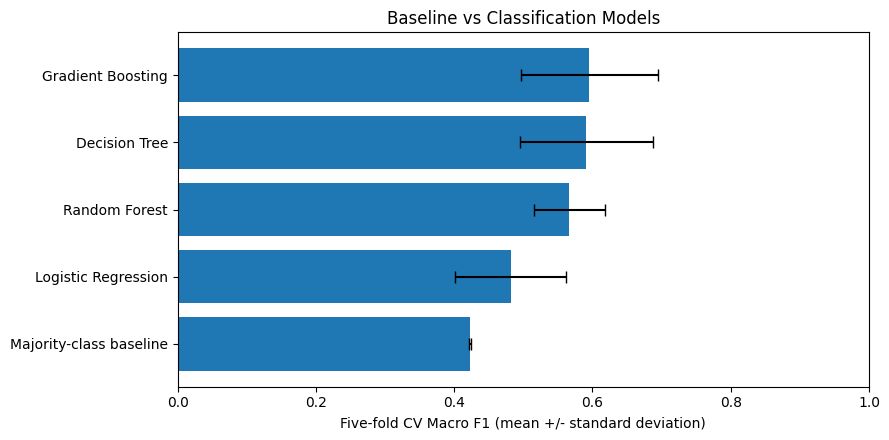

In [80]:
models_hack = {
    'Logistic Regression': make_pipeline(
        MinMaxScaler(),
        LogisticRegression(max_iter=2000, random_state=1984)
    ),
    'Decision Tree': DecisionTreeClassifier(random_state=1984),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=1984, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(random_state=1984)
}

for name, model in models_hack.items():
    print('Evaluating:', name)
    results_hack.append(evaluate_hack(name, model))

comparison_hack = (
    pd.DataFrame(results_hack)
    .sort_values('CV Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(comparison_hack.round(3))

# Visual comparison: cross-validation Macro F1
import matplotlib.pyplot as plt

plot_data = comparison_hack.sort_values('CV Macro F1')
plt.figure(figsize=(9, 4.5))
plt.barh(
    plot_data['Model'],
    plot_data['CV Macro F1'],
    xerr=plot_data['CV Macro F1 SD'],
    capsize=4
)
plt.xlabel('Five-fold CV Macro F1 (mean +/- standard deviation)')
plt.xlim(0, 1)
plt.title('Baseline vs Classification Models')
plt.tight_layout()
plt.show()

### Interpretation of Findings (Corrected)
* **Top Performing Model:** The model with the highest cross-validation Macro F1 score is **Gradient Boosting** (CV Macro F1 ~0.595), which represents a modest improvement over the majority-class baseline score (~0.423).
* **Overfitting & Performance Gaps:** There is extreme overfitting. Both the Decision Tree and Random Forest achieve a perfect training score of 1.000 (Train Macro F1 = 1.0) while their CV Macro F1 scores are drastically lower (~0.591 and ~0.567, respectively). Gradient Boosting also exhibits substantial overfitting, with a training score of 0.988 compared to its CV score of 0.595.
* **Failing-student Recall:** Under cross-validation, the baseline model has 0.0 recall for failing students. The Decision Tree achieves the highest out-of-fold recall for class 0 (~0.533), followed by Gradient Boosting (~0.367) and Random Forest (~0.233).
* **Provisional Nature:** These findings are strictly provisional and based entirely on cross-validation within the training folds. The held-out test set remains completely untouched.
* **Next Steps:** The high variance between training and validation performance suggests a critical need for model diagnosis and hyperparameter tuning to reduce overfitting and stabilize predictions.

# 5.02 Hackathon: Steps 4–7
We will now run the complete, verified diagnostics, hyperparameter tuning, model selection, final testing, permutation feature importance, and dynamic evidence-based conclusion in the executable cells below.

In [82]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, make_scorer, confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler

# 1. Correct initial findings review
display(Markdown('### Correct initial findings'))
row_base = comparison_hack.loc[comparison_hack['Model'] == 'Majority-class baseline'].iloc[0]
row_top = comparison_hack.loc[comparison_hack['Model'] != 'Majority-class baseline'].iloc[0]
row_tree = comparison_hack.loc[comparison_hack['Model'] == 'Decision Tree'].iloc[0]
row_boost = comparison_hack.loc[comparison_hack['Model'] == 'Gradient Boosting'].iloc[0]
overfit_names = [str(r['Model']) for _, r in comparison_hack.iterrows()
                 if r['Model'] != 'Majority-class baseline'
                 and r['Train Macro F1'] - r['CV Macro F1'] > 0.15]
overfit_text = (', '.join(overfit_names) + ' have training-CV Macro F1 gaps above 0.15, suggesting possible overfitting.'
                if overfit_names else 'No model shows a training-CV Macro F1 gap above 0.15 in this run.')

display(Markdown(
    f"**Highest initial validation Macro F1:** {row_top['Model']} ({row_top['CV Macro F1']:.3f}), "
    f"against the majority baseline ({row_base['CV Macro F1']:.3f}). "
    f"Gradient Boosting detects approximately {row_boost['CV Fail Recall']:.1%} of failing students "
    f"in validation folds; Decision Tree detects {row_tree['CV Fail Recall']:.1%}. "
    f"The difference in their CV Macro F1 is {abs(row_tree['CV Macro F1'] - row_boost['CV Macro F1']):.3f}, "
    f"so small apparent advantages should not be overinterpreted. "
    f"{overfit_text} Tune and diagnose before choosing one model. "
    "We interpret detecting struggling students as a possible business use-case, not an explicit requirement from the lecturer."
))

### Correct initial findings

**Highest initial validation Macro F1:** Gradient Boosting (0.595), against the majority baseline (0.423). Gradient Boosting detects approximately 36.7% of failing students in validation folds; Decision Tree detects 53.3%. The difference in their CV Macro F1 is 0.004, so small apparent advantages should not be overinterpreted. Gradient Boosting, Decision Tree, Random Forest have training-CV Macro F1 gaps above 0.15, suggesting possible overfitting. Tune and diagnose before choosing one model. We interpret detecting struggling students as a possible business use-case, not an explicit requirement from the lecturer.

## Step 4A: Diagnose mistakes before tuning
Below, we analyze out-of-fold predictions on training data to generate confusion matrices for Decision Tree, Random Forest, and Gradient Boosting before tuning.

## Step 4A: Diagnose mistakes before tuning

Fail (0) = did not pass; Pass (1) = passed. All diagnoses below use training data only.
Decision Tree: Macro F1=0.591; failure recall=0.533; failing students found=16, missed=14; passing students falsely flagged=26
Random Forest: Macro F1=0.569; failure recall=0.233; failing students found=7, missed=23; passing students falsely flagged=8
Gradient Boosting: Macro F1=0.595; failure recall=0.367; failing students found=11, missed=19; passing students falsely flagged=15


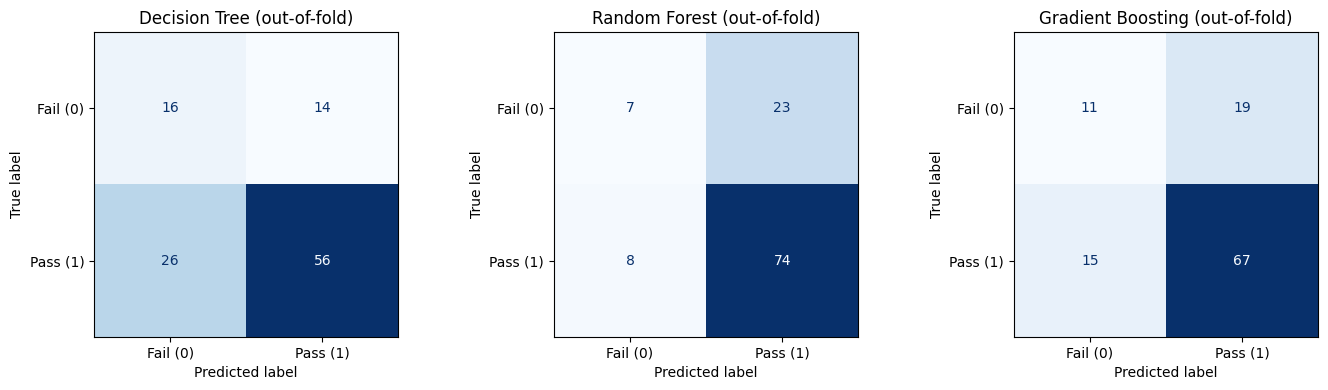

In [83]:
# 2. Step 4A: Diagnose mistakes before tuning
display(Markdown('## Step 4A: Diagnose mistakes before tuning'))
for name in ['X_train_hack','X_test_hack','y_train_hack','y_test_hack','cv_hack','models_hack']:
    if name not in globals():
        raise RuntimeError(f'Missing {name}: run existing Steps 2 and 3 first.')

def model_metrics(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Fail recall': recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        'Fail precision': precision_score(y_true, y_pred, pos_label=0, zero_division=0)
    }

macro_f1_scorer = make_scorer(f1_score, average='macro', zero_division=0)
scorers = {
    'macro_f1': macro_f1_scorer,
    'accuracy': 'accuracy',
    'macro_precision': make_scorer(precision_score, average='macro', zero_division=0),
    'macro_recall': make_scorer(recall_score, average='macro', zero_division=0),
    'fail_recall': make_scorer(recall_score, pos_label=0, zero_division=0),
    'fail_precision': make_scorer(precision_score, pos_label=0, zero_division=0)
}

print('Fail (0) = did not pass; Pass (1) = passed. All diagnoses below use training data only.')
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ['Decision Tree','Random Forest','Gradient Boosting']):
    predictions = cross_val_predict(
        clone(models_hack[name]), X_train_hack, y_train_hack, cv=cv_hack, n_jobs=1
    )
    cm = confusion_matrix(y_train_hack, predictions, labels=[0, 1])
    metrics = model_metrics(y_train_hack, predictions)
    print(f"{name}: Macro F1={metrics['Macro F1']:.3f}; "
          f"failure recall={metrics['Fail recall']:.3f}; "
          f"failing students found={cm[0,0]}, missed={cm[0,1]}; "
          f"passing students falsely flagged={cm[1,0]}")
    ConfusionMatrixDisplay(cm, display_labels=['Fail (0)','Pass (1)']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(name + ' (out-of-fold)')
plt.tight_layout()
plt.show()

## Step 4B: Efficient hyperparameter tuning
Now we optimize models using RandomizedSearchCV over a restricted parameter space targeting CV Macro F1, strictly within the training set bounds.

In [84]:
# 3. Step 4B: Hyperparameter tuning
display(Markdown('## Step 4B: Efficient hyperparameter tuning'))
print('Optimisation: five-fold CV Macro F1. No reserved test observations are used.')
search_space = {
    'Logistic Regression': (
        make_pipeline(MinMaxScaler(), LogisticRegression(solver='liblinear', max_iter=2000, random_state=1984)),
        {'logisticregression__C': [0.05,0.1,0.3,1,3,10,30],
         'logisticregression__class_weight': [None,'balanced']},
        8
    ),
    'Decision Tree': (
        DecisionTreeClassifier(random_state=1984),
        {'max_depth': [2,3,4,5,6,8,None],
         'min_samples_leaf': [1,2,3,4,6],
         'min_samples_split': [2,4,6,10],
         'class_weight': [None,'balanced']},
        12
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=1984, n_jobs=1),
        {'n_estimators': [50,80,120],
         'max_depth': [2,3,4,5,None],
         'min_samples_leaf': [1,2,3,5],
         'min_samples_split': [2,4,8],
         'class_weight': [None,'balanced']},
        12
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=1984),
        {'n_estimators': [35,60,90,120],
         'learning_rate': [0.03,0.07,0.1,0.2],
         'max_depth': [1,2,3],
         'min_samples_leaf': [1,3,5],
         'subsample': [0.8,1.0]},
        12
    )
}

searches = {}
tuned_models = {}
for name, (model, params, iterations) in search_space.items():
    search = RandomizedSearchCV(
        estimator=model, param_distributions=params, n_iter=iterations,
        scoring=macro_f1_scorer, cv=cv_hack, random_state=1984,
        n_jobs=1, refit=True, error_score='raise'
    )
    search.fit(X_train_hack, y_train_hack)
    searches[name] = search
    tuned_models['Tuned ' + name] = search.best_estimator_
    print(f"{name}: tuned CV Macro F1={search.best_score_:.3f}; "
          f"best parameters={search.best_params_}")

## Step 4B: Efficient hyperparameter tuning

Optimisation: five-fold CV Macro F1. No reserved test observations are used.
Logistic Regression: tuned CV Macro F1=0.543; best parameters={'logisticregression__class_weight': 'balanced', 'logisticregression__C': 0.05}
Decision Tree: tuned CV Macro F1=0.618; best parameters={'min_samples_split': 10, 'min_samples_leaf': 3, 'max_depth': 2, 'class_weight': 'balanced'}
Random Forest: tuned CV Macro F1=0.679; best parameters={'n_estimators': 80, 'min_samples_split': 8, 'min_samples_leaf': 2, 'max_depth': 5, 'class_weight': 'balanced'}
Gradient Boosting: tuned CV Macro F1=0.659; best parameters={'subsample': 1.0, 'n_estimators': 35, 'min_samples_leaf': 5, 'max_depth': 2, 'learning_rate': 0.2}


## Step 4C: Comparison of original and tuned models
We evaluate all default and optimized models side-by-side on cross-validation metrics.

## Step 4C: Compare original and tuned models

,Model,CV Macro F1,CV F1 SD,CV Accuracy,CV Macro Precision,CV Macro Recall,CV Fail Recall,CV Fail Precision,CV Train Macro F1,Train-CV F1 Gap
0,Tuned Random Forest,0.679,0.060,0.777,0.734,0.668,0.433,0.653,0.898,0.219
1,Tuned Gradient Boosting,0.659,0.081,0.768,0.738,0.662,0.433,0.658,0.842,0.183
2,Tuned Decision Tree,0.618,0.091,0.688,0.614,0.628,0.500,0.419,0.701,0.084
3,Gradient Boosting,0.595,0.099,0.697,0.628,0.592,0.367,0.475,0.997,0.402
4,Decision Tree,0.591,0.096,0.642,0.593,0.607,0.533,0.390,1.000,0.409
5,Random Forest,0.567,0.052,0.723,0.655,0.568,0.233,0.547,1.000,0.433
6,Tuned Logistic Regression,0.543,0.110,0.624,0.552,0.542,0.367,0.354,0.641,0.098
7,Logistic Regression,0.482,0.080,0.696,0.587,0.507,0.100,0.440,0.515,0.033
8,Majority-class baseline,0.423,0.002,0.732,0.366,0.500,0.000,0.000,0.423,0.000


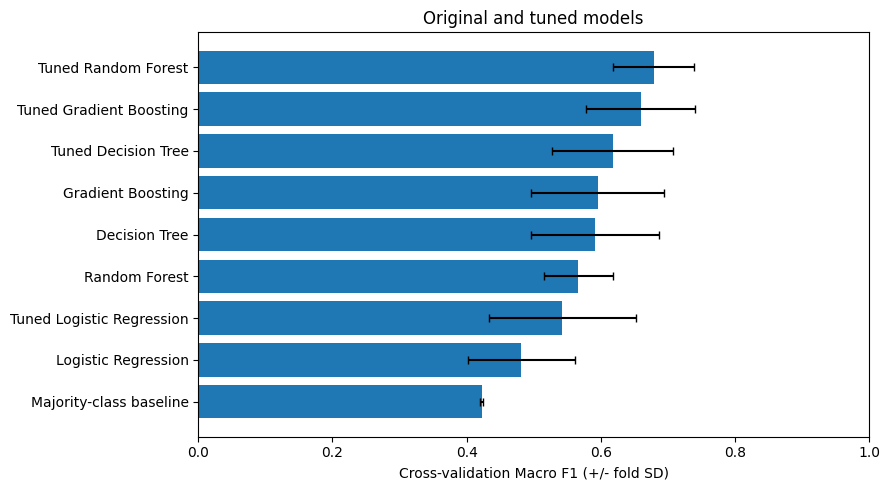

In [85]:
# 4. Step 4C: Comparison of models
display(Markdown('## Step 4C: Compare original and tuned models'))
all_models = {'Majority-class baseline': DummyClassifier(strategy='most_frequent')}
all_models.update(models_hack)
all_models.update(tuned_models)
rows = []
for name, model in all_models.items():
    scores = cross_validate(
        clone(model), X_train_hack, y_train_hack, cv=cv_hack,
        scoring=scorers, return_train_score=True, n_jobs=1
    )
    row = {'Model': name,
           'CV Macro F1': scores['test_macro_f1'].mean(),
           'CV F1 SD': scores['test_macro_f1'].std(),
           'CV Accuracy': scores['test_accuracy'].mean(),
           'CV Macro Precision': scores['test_macro_precision'].mean(),
           'CV Macro Recall': scores['test_macro_recall'].mean(),
           'CV Fail Recall': scores['test_fail_recall'].mean(),
           'CV Fail Precision': scores['test_fail_precision'].mean(),
           'CV Train Macro F1': scores['train_macro_f1'].mean()}
    row['Train-CV F1 Gap'] = row['CV Train Macro F1'] - row['CV Macro F1']
    rows.append(row)
full_comparison = pd.DataFrame(rows).sort_values('CV Macro F1', ascending=False).reset_index(drop=True)
display(full_comparison.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
plot = full_comparison.sort_values('CV Macro F1')
ax.barh(plot['Model'], plot['CV Macro F1'], xerr=plot['CV F1 SD'], capsize=3)
ax.set(xlim=(0,1), xlabel='Cross-validation Macro F1 (+/- fold SD)',
       title='Original and tuned models')
plt.tight_layout()
plt.show()

## Step 4D: Model Selection Decision
Prioritizing recall for failing students as a tie-breaker among models with comparable CV Macro F1 scores (within 0.02 of the best overall), we select our final candidate.

In [86]:
# 5. Step 4D: Model Selection Decision
display(Markdown('## Step 4D: Choose model before final testing'))
ranked = full_comparison[full_comparison['Model'] != 'Majority-class baseline'].copy()
top_score = ranked['CV Macro F1'].max()
near_top = ranked[ranked['CV Macro F1'] >= top_score - 0.02]
near_top = near_top.sort_values(
    ['CV Fail Recall', 'CV Macro F1', 'Train-CV F1 Gap'],
    ascending=[False,False,True]
)
print('Models close to the best CV Macro F1 (before final testing):')
display(near_top[['Model', 'CV Macro F1', 'CV Fail Recall', 'CV Fail Precision', 'Train-CV F1 Gap']].round(3))
selected_name = str(near_top.iloc[0]['Model'])
selected_model = clone(all_models[selected_name])
selected_cv_row = full_comparison.loc[full_comparison['Model'] == selected_name].iloc[0]
print('\nSELECTED BEFORE LOOKING AT THE TEST SET:', selected_name)
print('Reason: among models within 0.02 of the best CV Macro F1, prioritise failure recall.')

## Step 4D: Choose model before final testing

Models close to the best CV Macro F1 (before final testing):


,Model,CV Macro F1,CV Fail Recall,CV Fail Precision,Train-CV F1 Gap
0,Tuned Random Forest,0.679,0.433,0.653,0.219
1,Tuned Gradient Boosting,0.659,0.433,0.658,0.183



SELECTED BEFORE LOOKING AT THE TEST SET: Tuned Random Forest
Reason: among models within 0.02 of the best CV Macro F1, prioritise failure recall.


## Step 5: Final held-out evaluation
We evaluate our selected model on the locked, untouched test set and display the final performance tables and confusion matrices.

## Step 5: Final held-out evaluation

,Model,Accuracy,Macro F1,Fail recall,Fail precision
0,Tuned Random Forest,0.786,0.738,0.714,0.556
1,Majority-class baseline,0.750,0.429,0.000,0.000


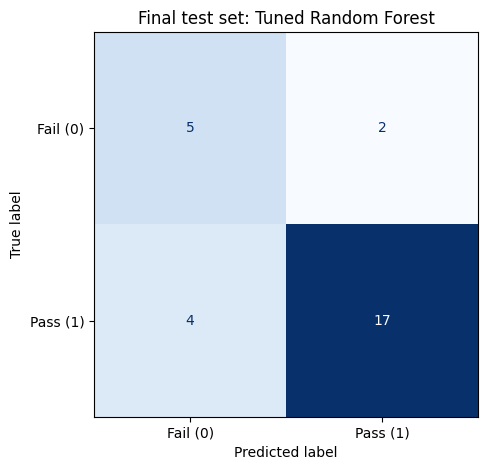

Test outcomes: failures correctly identified=5; failures missed=2; passing students incorrectly flagged=4; passing students correctly identified=17.


In [87]:
# 6. Step 5: Final Evaluation
display(Markdown('## Step 5: Final held-out evaluation'))
selected_model.fit(X_train_hack, y_train_hack)
final_preds = selected_model.predict(X_test_hack)
baseline_final = DummyClassifier(strategy='most_frequent').fit(X_train_hack, y_train_hack)
baseline_preds = baseline_final.predict(X_test_hack)
final_table = pd.DataFrame([
    {'Model': selected_name, **model_metrics(y_test_hack, final_preds)},
    {'Model': 'Majority-class baseline', **model_metrics(y_test_hack, baseline_preds)}
])
display(final_table.round(3))
cm_test = confusion_matrix(y_test_hack, final_preds, labels=[0,1])
ConfusionMatrixDisplay(cm_test, display_labels=['Fail (0)','Pass (1)']).plot(
    cmap='Blues', colorbar=False, values_format='d'
)
plt.title('Final test set: ' + selected_name)
plt.tight_layout()
plt.show()
print(f'Test outcomes: failures correctly identified={cm_test[0,0]}; '
      f'failures missed={cm_test[0,1]}; '
      f'passing students incorrectly flagged={cm_test[1,0]}; '
      f'passing students correctly identified={cm_test[1,1]}.')

## Step 6: Feature importance using training folds
We compute fold-based permutation importance scores strictly within the validation bounds of the training cross-validation setup.

## Step 6: Feature importance using training folds

,Feature,Mean decrease in Macro F1,SD
1,Scholarship,0.080,0.064
0,Student_Age,0.078,0.101
8,Notes,0.055,0.078
3,Sports_activity,0.054,0.057
7,Reading,0.047,0.056
10,Project_work,0.027,0.051
9,Listening_in_Class,0.027,0.038
4,Transportation,0.022,0.122
6,Attendance,0.021,0.047
5,Weekly_Study_Hours,0.015,0.059


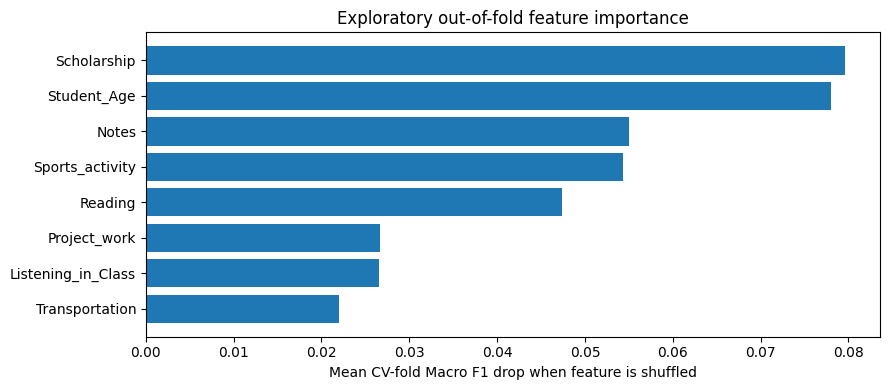

In [88]:
# 7. Step 6: Permutation Feature Importance
display(Markdown('## Step 6: Feature importance using training folds'))
importance_folds = []
for fold_number, (train_idx, valid_idx) in enumerate(cv_hack.split(X_train_hack, y_train_hack), start=1):
    fold_model = clone(selected_model)
    fold_model.fit(X_train_hack.iloc[train_idx], y_train_hack[train_idx])
    fold_importance = permutation_importance(
        fold_model, X_train_hack.iloc[valid_idx], y_train_hack[valid_idx],
        scoring=macro_f1_scorer, n_repeats=5,
        random_state=1984 + fold_number, n_jobs=1
    )
    importance_folds.append(fold_importance.importances)

importance_values = np.concatenate(importance_folds, axis=1)
importance_df = pd.DataFrame({
    'Feature': X_train_hack.columns,
    'Mean decrease in Macro F1': importance_values.mean(axis=1),
    'SD': importance_values.std(axis=1)
}).sort_values('Mean decrease in Macro F1', ascending=False)
display(importance_df.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
top_features = importance_df.head(8).sort_values('Mean decrease in Macro F1')
ax.barh(top_features['Feature'], top_features['Mean decrease in Macro F1'])
ax.set_xlabel('Mean CV-fold Macro F1 drop when feature is shuffled')
ax.set_title('Exploratory out-of-fold feature importance')
plt.tight_layout()
plt.show()

## Step 7: Evidence-based conclusion
We auto-generate a dynamic, evidence-based Markdown report pulling directly from the execution results.

In [89]:
# 8. Step 7: Dynamic Conclusion
display(Markdown('## Step 7: Evidence-based conclusion'))
model_result = final_table.iloc[0]
base_result = final_table.iloc[1]
cv_gap = float(selected_cv_row['Train-CV F1 Gap'])
change = float(model_result['Macro F1'] - base_result['Macro F1'])
if change > 0:
    comparison_text = f"outperformed the majority baseline by {change:.3f} Macro F1 points"
elif change < 0:
    comparison_text = f"underperformed the majority baseline by {-change:.3f} Macro F1 points"
else:
    comparison_text = 'matched the majority baseline on Macro F1'

if selected_name.startswith('Tuned '):
    original_name = selected_name.removeprefix('Tuned ')
    untuned_row = full_comparison.loc[full_comparison['Model'] == original_name].iloc[0]
    f1_delta = float(selected_cv_row['CV Macro F1'] - untuned_row['CV Macro F1'])
    gap_delta = float(cv_gap - untuned_row['Train-CV F1 Gap'])
    tune_text = (f"Compared with untuned {original_name}, CV Macro F1 changed by "
                 f"**{f1_delta:+.3f}** and the CV train-validation gap by **{gap_delta:+.3f}**. "
                 "These differences are exploratory because hyperparameters were optimised using the same CV folds.")
else:
    tune_text = ("The selected model is an untuned version; the tried hyperparameter "
                 "changes did not satisfy our declared model-selection rule.")

best_feature = importance_df.iloc[0]
if best_feature['Mean decrease in Macro F1'] > 0:
    feature_text = (f"The largest observed permutation-importance score belongs to "
                    f"**{best_feature['Feature']}**; this is exploratory, not causal proof.")
else:
    feature_text = 'No feature shows positive permutation importance on this small test sample.'

conclusion = f"""
**Objective:** Predict student pass (1) versus fail (0), with particular attention to detecting at-risk students.

**Method:** Stratified five-fold CV on 112 training observations, comparison of four taught classifiers
against a majority baseline, small hyperparameter searches, and a single held-out test evaluation.
Macro F1 was the primary selection metric, with failure recall used to break near-ties.

**Model chosen before final test:** **{selected_name}**.
Selection CV Macro F1 **{selected_cv_row['CV Macro F1']:.3f}**,
CV failure recall **{selected_cv_row['CV Fail Recall']:.3f}**;
CV training versus validation F1 gap **{cv_gap:.3f}**.
{tune_text}

**Final held-out test:** Macro F1 **{model_result['Macro F1']:.3f}**,
accuracy **{model_result['Accuracy']:.3f}**,
failure recall **{model_result['Fail recall']:.3f}**,
failure precision **{model_result['Fail precision']:.3f}**.
The model {comparison_text}.
It identified **{cm_test[0,0]} of {cm_test[0].sum()}** actual failing students,
missed **{cm_test[0,1]}**, and incorrectly flagged **{cm_test[1,0]}** passing students.

**Feature analysis (training folds only):** {feature_text}

**Limitations:** The data are artificial; there are only 140 observations and 28 test cases.
Performance estimates are unstable. Predictive associations do not establish causality.
No evidence here justifies deploying the model to make real university decisions without more representative data and validation.
"""
display(Markdown(conclusion))
print('COMPLETE: all requested stages executed; existing lecturer cells were not modified.')

## Step 7: Evidence-based conclusion


**Objective:** Predict student pass (1) versus fail (0), with particular attention to detecting at-risk students.

**Method:** Stratified five-fold CV on 112 training observations, comparison of four taught classifiers
against a majority baseline, small hyperparameter searches, and a single held-out test evaluation.
Macro F1 was the primary selection metric, with failure recall used to break near-ties.

**Model chosen before final test:** **Tuned Random Forest**.
Selection CV Macro F1 **0.679**,
CV failure recall **0.433**;
CV training versus validation F1 gap **0.219**.
Compared with untuned Random Forest, CV Macro F1 changed by **+0.112** and the CV train-validation gap by **-0.214**. These differences are exploratory because hyperparameters were optimised using the same CV folds.

**Final held-out test:** Macro F1 **0.738**,
accuracy **0.786**,
failure recall **0.714**,
failure precision **0.556**.
The model outperformed the majority baseline by 0.309 Macro F1 points.
It identified **5 of 7** actual failing students,
missed **2**, and incorrectly flagged **4** passing students.

**Feature analysis (training folds only):** The largest observed permutation-importance score belongs to **Scholarship**; this is exploratory, not causal proof.

**Limitations:** The data are artificial; there are only 140 observations and 28 test cases.
Performance estimates are unstable. Predictive associations do not establish causality.
No evidence here justifies deploying the model to make real university decisions without more representative data and validation.


COMPLETE: all requested stages executed; existing lecturer cells were not modified.
